# Testing portfolio sensitivity to covariance cleaning

The global minimum-variance portfolio gives the fully invested weights with the smallest variance under the supplied covariance matrix:

$$
w_{\mathrm{GMV}}(\Sigma)
=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
\mathbf 1^{\mathsf T}w_{\mathrm{GMV}}=1.
$$

Here, $\Sigma$ is an invertible covariance matrix; $\Sigma^{-1}$ is its inverse; $\mathbf 1$ is a vector of ones. $w_{\mathrm{GMV}}$ is the weight vector; $\mathsf T$ denotes transpose; the denominator rescales the weights to sum to one.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.data.denoise import corr_to_cov, cov_to_corr, denoise_cov, denoised_corr, denoised_corr2, find_max_eval, fit_kde, marcenko_pastur_pdf, nercome_denoised_covariance, optimal_portfolio, pca
from RiskLabAI.data.denoise.denoising import optimal_portfolio_denoised

FIGURES = ROOT / "outputs" / "figures" / "10_covariance_denoising"
TABLES = ROOT / "outputs" / "tables" / "10_covariance_denoising"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Why Small Eigenvalues Matter

The bound shows how a small covariance change can create a much larger change in its inverse when the condition number is large:

$$
\frac{\lVert(\Sigma+\Delta)^{-1}-\Sigma^{-1}\rVert_2}{\lVert\Sigma^{-1}\rVert_2}
\leq
\frac{\kappa_2(\Sigma)\,\lVert\Delta\rVert_2/\lVert\Sigma\rVert_2}
{1-\kappa_2(\Sigma)\,\lVert\Delta\rVert_2/\lVert\Sigma\rVert_2},
\qquad
\kappa_2(\Sigma)\frac{\lVert\Delta\rVert_2}{\lVert\Sigma\rVert_2}<1.
$$

Here, $\Sigma$ is the original positive-definite covariance; $\Delta$ is a perturbation; $\kappa_2(\Sigma)$ is its spectral condition number. $\lVert\cdot\rVert_2$ is the spectral norm; $(\Sigma+\Delta)^{-1}$ and $\Sigma^{-1}$ are the perturbed and original inverses. The final inequality is the condition required for the displayed finite upper bound.

In [2]:
base_window = industry_returns.iloc[:125]
base_covariance = np.cov(base_window.to_numpy(), rowvar=False)
base_correlation = cov_to_corr(base_covariance)
perturbation_levels = np.logspace(-8, -2, 13)
perturbation_rows = []
rng = np.random.default_rng(9027)
direction = rng.standard_normal(base_covariance.shape)
direction = (direction + direction.T) / 2.0
direction /= np.linalg.norm(direction, ord=2)
for relative_size in perturbation_levels:
    perturbation = direction * relative_size * np.linalg.norm(base_covariance, ord=2)
    if np.linalg.eigvalsh(base_covariance + perturbation).min() <= 0.0:
        perturbation = np.eye(base_covariance.shape[0]) * relative_size * np.linalg.norm(base_covariance, ord=2)
    relative_inverse_change = np.linalg.norm(np.linalg.inv(base_covariance + perturbation) - np.linalg.inv(base_covariance), ord=2) / np.linalg.norm(np.linalg.inv(base_covariance), ord=2)
    condition_product = np.linalg.cond(base_covariance) * np.linalg.norm(perturbation, ord=2) / np.linalg.norm(base_covariance, ord=2)
    upper_bound = condition_product / (1.0 - condition_product) if condition_product < 1.0 else np.nan
    perturbation_rows.append({"Relative covariance change": np.linalg.norm(perturbation, ord=2) / np.linalg.norm(base_covariance, ord=2), "Relative inverse change": relative_inverse_change, "Condition product": condition_product, "Finite upper bound": upper_bound})
inverse_sensitivity = pd.DataFrame(perturbation_rows)
inverse_sensitivity_display = inverse_sensitivity.iloc[[0, 2, 4, 6, 8, 10, 12]].copy()
save_table(inverse_sensitivity_display, "inverse_sensitivity", "Inverse sensitivity for controlled perturbations of a public sample covariance.", "tab:chapter9-inverse-sensitivity", fit=True)
display(inverse_sensitivity_display.round(8))

,Relative covariance change,Relative inverse change,Condition product,Finite upper bound
0,1.000000e-08,0.000003,0.000012,0.000012
2,1.000000e-07,0.000030,0.000118,0.000118
4,1.000000e-06,0.000298,0.001178,0.001179
6,1.000000e-05,0.002994,0.011781,0.011921
8,1.000000e-04,0.031027,0.117807,0.133539
10,1.000000e-03,0.484817,1.178068,NaN
12,1.000000e-02,0.921757,11.780683,NaN


## Known-Truth Weight Recovery

The first quantity measures weight error against the known optimal portfolio, and the second measures variance under the known covariance:

$$
\operatorname{RMSE}_w(m)
=\sqrt{\frac{1}{N}\sum_{i=1}^{N}\left(\widehat w_{i,m}-w_{i,0}\right)^2},
\qquad
V_m=\widehat w_m^{\mathsf T}\Sigma_0\widehat w_m.
$$

Here, $N$ is the number of portfolios; $i$ indexes a portfolio; $m$ names a covariance method. $\widehat w_{i,m}$ is estimated weight $i$; $w_{i,0}$ is its known-truth value; $\operatorname{RMSE}_w(m)$ is root mean squared weight error. $\widehat w_m$ is the full estimated weight vector; $\Sigma_0$ is the known covariance; $V_m$ is realized true variance; $\mathsf T$ denotes transpose.

,Method,Mean weight root mean squared error,Median weight root mean squared error,Mean weight absolute error,Mean realized true variance,Mean gross exposure
0,Sample covariance,0.046639,0.04620,1.789231,0.000032,2.176976
1,Cleaned covariance,0.023018,0.02315,0.881712,0.000021,1.370083
2,One-step cleaned covariance,0.023018,0.02315,0.881712,0.000021,1.370083


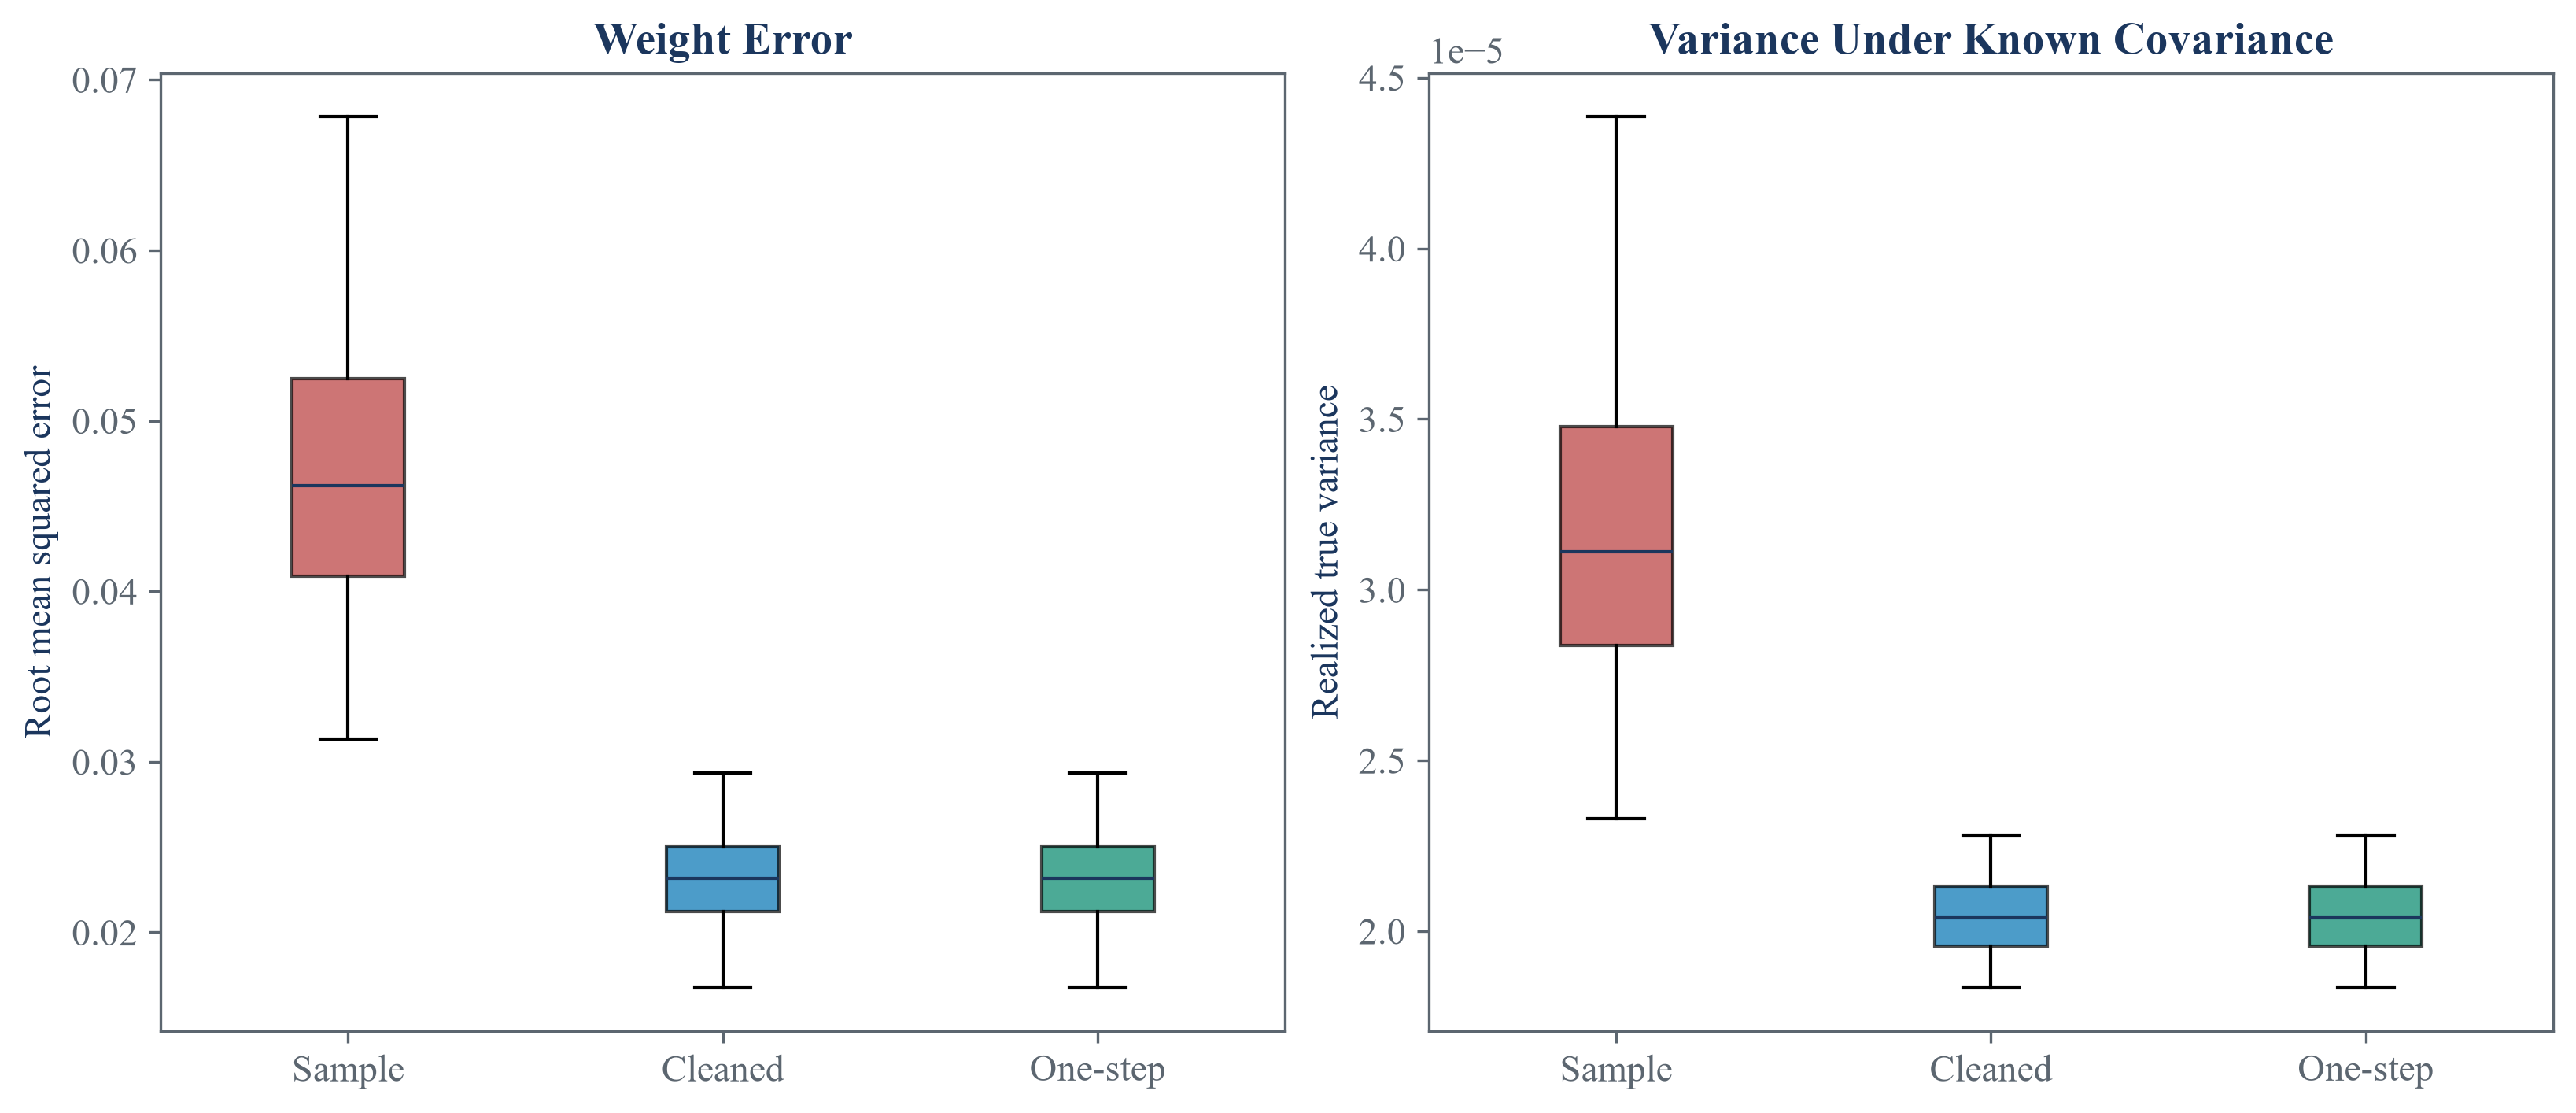

In [3]:
weight_block_size = 7
weight_block_count = 7
weight_correlation = 0.50
weight_observations = 100
weight_repetitions = 100
weight_block = (1.0 - weight_correlation) * np.eye(weight_block_size) + weight_correlation * np.ones((weight_block_size, weight_block_size))
weight_true_correlation = np.kron(np.eye(weight_block_count), weight_block)
weight_true_scale = industry_returns.std(ddof=1).to_numpy()
weight_true_covariance = corr_to_cov(weight_true_correlation, weight_true_scale)
weight_true_portfolio = optimal_portfolio(weight_true_covariance)
weight_q_ratio = weight_observations / weight_true_covariance.shape[0]
weight_rows = []
one_step_differences = []
for repetition in range(weight_repetitions):
    random_generator = np.random.default_rng(9300 + repetition)
    simulated_returns = random_generator.multivariate_normal(np.zeros(weight_true_covariance.shape[0]), weight_true_covariance, size=weight_observations)
    sample_estimate = np.cov(simulated_returns, rowvar=False)
    cleaned_estimate = denoise_cov(sample_estimate, weight_q_ratio, bandwidth=0.01)
    sample_weights = optimal_portfolio(sample_estimate)
    cleaned_weights = optimal_portfolio(cleaned_estimate)
    one_step_weights = optimal_portfolio_denoised(sample_estimate, weight_q_ratio, bandwidth=0.01)
    one_step_differences.append(np.max(np.abs(cleaned_weights - one_step_weights)))
    for method, weights in [("Sample covariance", sample_weights), ("Cleaned covariance", cleaned_weights), ("One-step cleaned covariance", one_step_weights)]:
        weight_rows.append({"Repetition": repetition + 1, "Method": method, "Weight root mean squared error": np.sqrt(np.mean((weights - weight_true_portfolio) ** 2)), "Weight absolute error": np.sum(np.abs(weights - weight_true_portfolio)), "Realized true variance": float(weights.T @ weight_true_covariance @ weights), "Gross exposure": np.sum(np.abs(weights))})
weight_recovery_runs = pd.DataFrame(weight_rows)
weight_summary_rows = []
for method, group in weight_recovery_runs.groupby("Method", sort=False):
    weight_summary_rows.append({"Method": method, "Mean weight root mean squared error": group["Weight root mean squared error"].mean(), "Median weight root mean squared error": group["Weight root mean squared error"].median(), "Mean weight absolute error": group["Weight absolute error"].mean(), "Mean realized true variance": group["Realized true variance"].mean(), "Mean gross exposure": group["Gross exposure"].mean()})
weight_recovery_summary = pd.DataFrame(weight_summary_rows)
save_table(weight_recovery_summary, "weight_recovery_summary", "Known-truth portfolio weight and variance errors across one hundred repetitions.", "tab:chapter9-weight-recovery", fit=True)
display(weight_recovery_summary.round(6))

weight_methods = ["Sample covariance", "Cleaned covariance", "One-step cleaned covariance"]
weight_method_colors = [palette["rose"], palette["cyan"], palette["green"]]
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), constrained_layout=True)
rmse_box = axes[0].boxplot([weight_recovery_runs.loc[weight_recovery_runs["Method"] == method, "Weight root mean squared error"] for method in weight_methods], tick_labels=["Sample", "Cleaned", "One-step"], patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
variance_box = axes[1].boxplot([weight_recovery_runs.loc[weight_recovery_runs["Method"] == method, "Realized true variance"] for method in weight_methods], tick_labels=["Sample", "Cleaned", "One-step"], patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
for patch, color in zip(rmse_box["boxes"], weight_method_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)
for patch, color in zip(variance_box["boxes"], weight_method_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)
axes[0].set_title("Weight Error")
axes[0].set_ylabel("Root mean squared error")
axes[1].set_title("Variance Under Known Covariance")
axes[1].set_ylabel("Realized true variance")
figure.savefig(FIGURES / "known_truth_weight_recovery.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "known_truth_weight_recovery.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "known_truth_weight_recovery.png")))
plt.close(figure)

## Evaluating rolling portfolios out of sample

The first quantity is annualized volatility measured after weight selection, and the second records weight changes between evaluation windows:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}
=\sqrt{252}\,\operatorname{sd}\!\left(R_k^{\mathrm{test}}w_{k,m}\right),
\qquad
\operatorname{turnover}_{k,m}
=\frac{1}{2}\lVert w_{k,m}-w_{k-1,m}\rVert_1.
$$

Here, $k$ labels a rolling window; $m$ labels a covariance method; $R_k^{\mathrm{test}}$ is its held-out return matrix. $w_{k,m}$ contains weights chosen from the preceding training window; $\operatorname{sd}$ is sample standard deviation; $252$ is trading days per year. $\lVert\cdot\rVert_1$ is the sum of absolute entries; turnover is one half of the total absolute weight change.

In [4]:
training_days = 125
testing_days = 21
step_days = 63
rolling_rows = []
previous_weights = {}
fold_number = 0
for training_end in range(training_days, len(industry_returns) - testing_days + 1, step_days):
    training = industry_returns.iloc[training_end - training_days:training_end]
    testing = industry_returns.iloc[training_end:training_end + testing_days]
    covariance_sample = np.cov(training.to_numpy(), rowvar=False)
    q_fold = training_days / covariance_sample.shape[0]
    covariance_constant = denoise_cov(covariance_sample, q_fold, bandwidth=0.05)
    correlation_fold = cov_to_corr(covariance_sample)
    values_fold, vectors_fold = pca(correlation_fold)
    cutoff_fold, _ = find_max_eval(np.diag(values_fold), q_fold, 0.05)
    factors_fold = int(np.sum(values_fold > cutoff_fold))
    correlation_targeted = denoised_corr2(np.diag(values_fold), vectors_fold, factors_fold, alpha=0.5)
    covariance_targeted = corr_to_cov(correlation_targeted, np.sqrt(np.diag(covariance_sample)))
    method_weights = {
        "Sample covariance": optimal_portfolio(covariance_sample),
        "Constant residual": optimal_portfolio(covariance_constant),
        "Targeted, alpha 0.5": optimal_portfolio(covariance_targeted),
        "Equal weight": np.repeat(1.0 / covariance_sample.shape[0], covariance_sample.shape[0]),
    }
    fold_number += 1
    for method, weights in method_weights.items():
        held_out_returns = testing.to_numpy() @ weights
        turnover = np.nan if method not in previous_weights else 0.5 * np.sum(np.abs(weights - previous_weights[method]))
        rolling_rows.append({"Fold": fold_number, "Training end": str(training.index.max().date()), "Test start": str(testing.index.min().date()), "Test end": str(testing.index.max().date()), "Method": method, "Annualized test volatility": np.std(held_out_returns, ddof=1) * np.sqrt(252.0), "Gross exposure": np.sum(np.abs(weights)), "Largest absolute weight": np.max(np.abs(weights)), "Weight concentration": np.sum(weights ** 2), "Turnover": turnover, "Weight sum": weights.sum(), "Signal directions": factors_fold})
        previous_weights[method] = weights
rolling_results = pd.DataFrame(rolling_rows)
sample_risk = rolling_results.loc[rolling_results["Method"] == "Sample covariance"].set_index("Fold")["Annualized test volatility"]
summary_rows = []
weight_rows = []
pairwise_rows = []
for method, group in rolling_results.groupby("Method", sort=False):
    risk = group.set_index("Fold")["Annualized test volatility"]
    summary_rows.append({"Method": method, "Mean annualized test volatility": risk.mean(), "Median annualized test volatility": risk.median(), "Smallest annualized test volatility": risk.min(), "Largest annualized test volatility": risk.max()})
    weight_rows.append({"Method": method, "Median gross exposure": group["Gross exposure"].median(), "Median largest absolute weight": group["Largest absolute weight"].median(), "Median weight concentration": group["Weight concentration"].median(), "Mean turnover": group["Turnover"].mean()})
    pairwise_rows.append({"Method": method, "Mean volatility ratio to sample": np.mean(risk.to_numpy() / sample_risk.to_numpy()), "Folds below sample volatility": int(np.sum(risk.to_numpy() < sample_risk.to_numpy())), "Total folds": len(risk)})
rolling_portfolio_summary = pd.DataFrame(summary_rows)
rolling_weight_summary = pd.DataFrame(weight_rows)
rolling_pairwise_summary = pd.DataFrame(pairwise_rows)
rolling_sample_summary = pd.DataFrame({"Quantity": ["Training days", "Testing days", "Step days", "Rolling folds", "First test date", "Last test date", "Portfolios"], "Value": [training_days, testing_days, step_days, fold_number, rolling_results["Test start"].min(), rolling_results["Test end"].max(), industry_returns.shape[1]]})
save_table(rolling_sample_summary, "rolling_sample_summary", "Chronological design of the public rolling comparison.", "tab:chapter9-rolling-design", fit=True)
save_table(rolling_portfolio_summary, "rolling_portfolio_summary", "Held-out volatility across public rolling windows.", "tab:chapter9-rolling-risk", fit=True)
save_table(rolling_weight_summary, "rolling_weight_summary", "Weight size and turnover across public rolling windows.", "tab:chapter9-rolling-weights", fit=True)
save_table(rolling_pairwise_summary, "rolling_pairwise_summary", "Fold-by-fold volatility comparisons with the sample covariance portfolio.", "tab:chapter9-rolling-pairwise", fit=True)
display(rolling_sample_summary)
display(rolling_portfolio_summary.round(6))
display(rolling_weight_summary.round(6))
display(rolling_pairwise_summary.round(6))

,Quantity,Value
0,Training days,125
1,Testing days,21
2,Step days,63
3,Rolling folds,26
4,First test date,2019-07-02
5,Last test date,2025-11-04
6,Portfolios,49


,Method,Mean annualized test volatility,Median annualized test volatility,Smallest annualized test volatility,Largest annualized test volatility
0,Sample covariance,0.145330,0.154405,0.086520,0.248425
1,Constant residual,0.141410,0.115449,0.077423,0.439279
2,"Targeted, alpha 0.5",0.123074,0.108938,0.074390,0.221472
3,Equal weight,0.167121,0.143458,0.090966,0.463878


,Method,Median gross exposure,Median largest absolute weight,Median weight concentration,Mean turnover
0,Sample covariance,5.396854,0.431834,1.048719,2.754571
1,Constant residual,2.876059,0.266240,0.329794,1.153032
2,"Targeted, alpha 0.5",3.485929,0.290891,0.446881,1.346525
3,Equal weight,1,0.020408,0.020408,0


,Method,Mean volatility ratio to sample,Folds below sample volatility,Total folds
0,Sample covariance,1,0,26
1,Constant residual,0.952435,16,26
2,"Targeted, alpha 0.5",0.850034,23,26
3,Equal weight,1.140760,8,26


## Measuring portfolio stability

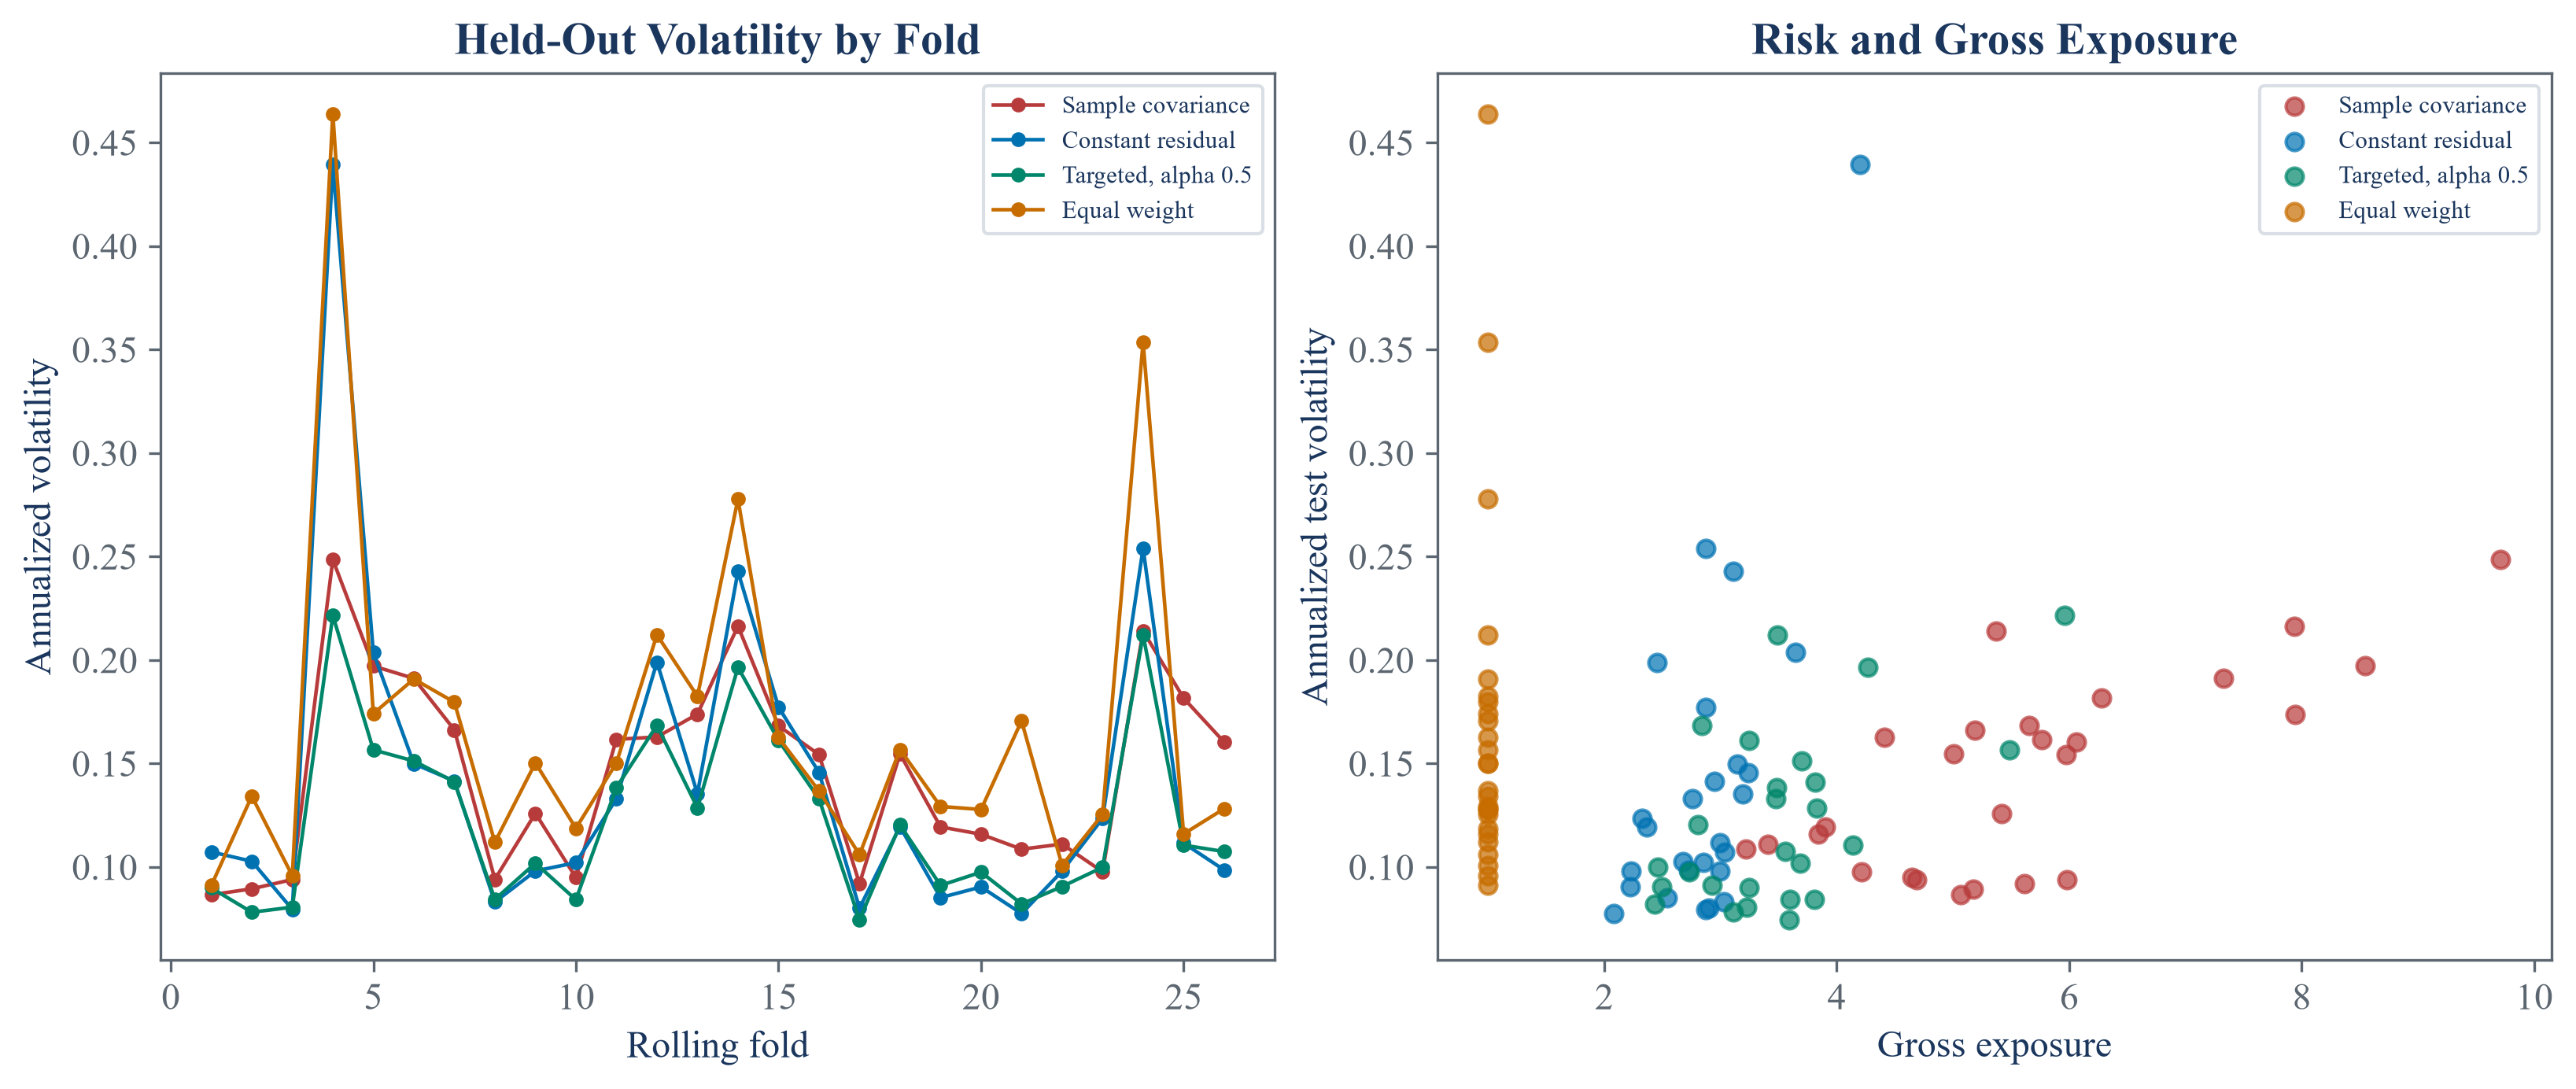

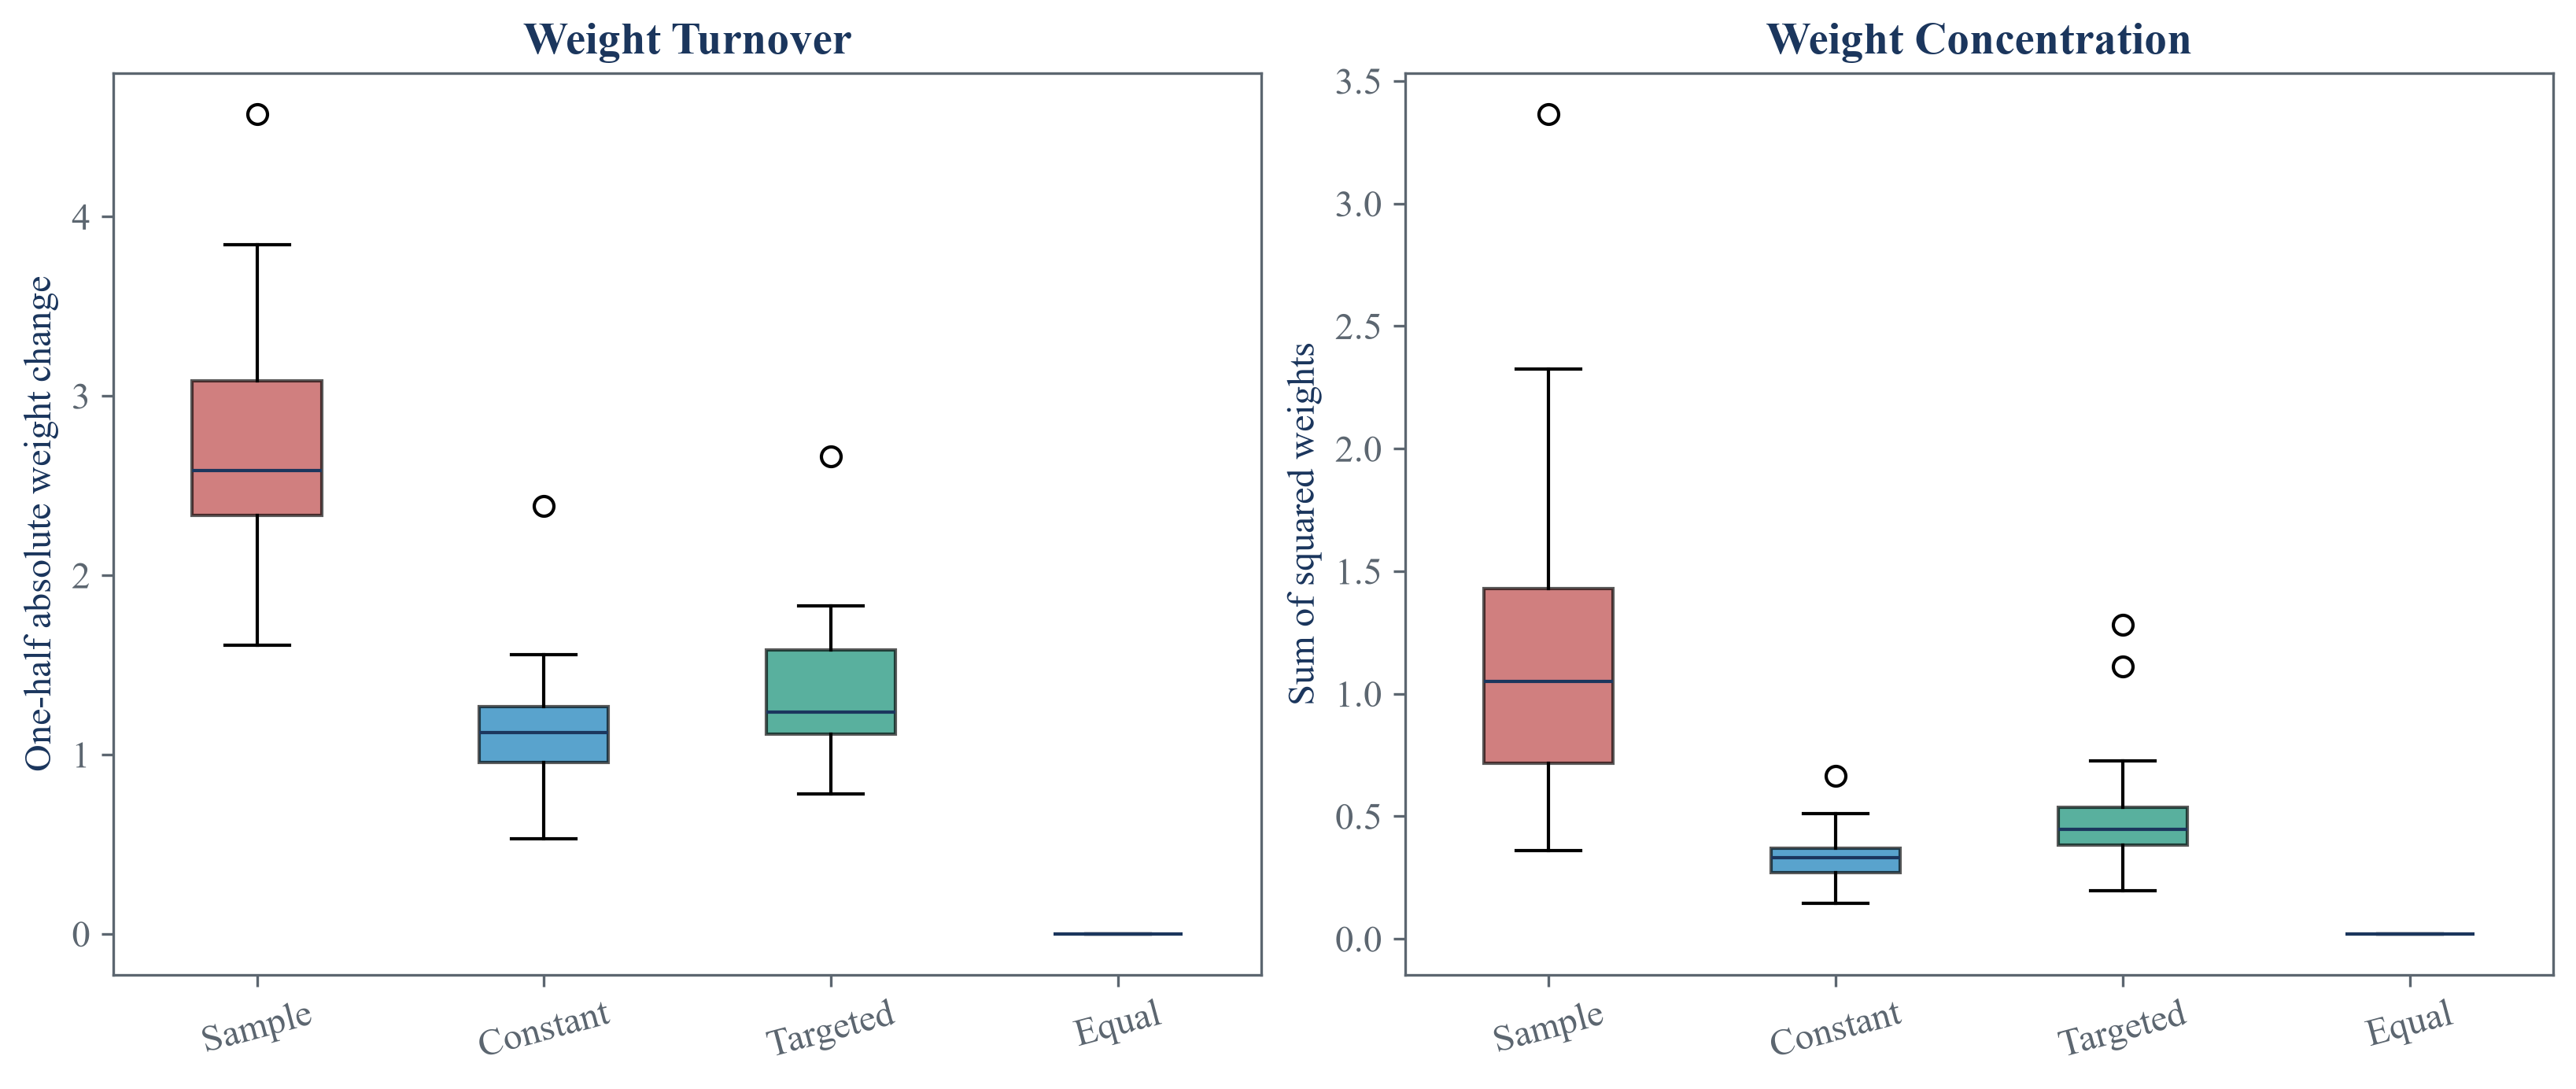

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), constrained_layout=True)
method_colors = {"Sample covariance": palette["rose"], "Constant residual": palette["cyan"], "Targeted, alpha 0.5": palette["green"], "Equal weight": palette["amber"]}
for method, group in rolling_results.groupby("Method", sort=False):
    axes[0].plot(group["Fold"], group["Annualized test volatility"], marker="o", markersize=3.5, linewidth=1.1, color=method_colors[method], label=method)
axes[0].set_title("Held-Out Volatility by Fold")
axes[0].set_xlabel("Rolling fold")
axes[0].set_ylabel("Annualized volatility")
axes[0].legend(fontsize=7.5)
for method, group in rolling_results.groupby("Method", sort=False):
    axes[1].scatter(group["Gross exposure"], group["Annualized test volatility"], s=28, alpha=0.7, color=method_colors[method], label=method)
axes[1].set_title("Risk and Gross Exposure")
axes[1].set_xlabel("Gross exposure")
axes[1].set_ylabel("Annualized test volatility")
axes[1].legend(fontsize=7.5)
figure.savefig(FIGURES / "rolling_portfolio_risk.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "rolling_portfolio_risk.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "rolling_portfolio_risk.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), constrained_layout=True)
methods = list(method_colors)
positions = np.arange(len(methods))
turnover_values = [rolling_results.loc[rolling_results["Method"] == method, "Turnover"].dropna().to_numpy() for method in methods]
concentration_values = [rolling_results.loc[rolling_results["Method"] == method, "Weight concentration"].to_numpy() for method in methods]
turnover_plot = axes[0].boxplot(turnover_values, positions=positions, patch_artist=True, medianprops={"color": palette["text"]})
concentration_plot = axes[1].boxplot(concentration_values, positions=positions, patch_artist=True, medianprops={"color": palette["text"]})
for patch, method in zip(turnover_plot["boxes"], methods):
    patch.set_facecolor(method_colors[method])
    patch.set_alpha(0.65)
for patch, method in zip(concentration_plot["boxes"], methods):
    patch.set_facecolor(method_colors[method])
    patch.set_alpha(0.65)
short_labels = ["Sample", "Constant", "Targeted", "Equal"]
axes[0].set_xticks(positions, short_labels, rotation=15)
axes[1].set_xticks(positions, short_labels, rotation=15)
axes[0].set_title("Weight Turnover")
axes[0].set_ylabel("One-half absolute weight change")
axes[1].set_title("Weight Concentration")
axes[1].set_ylabel("Sum of squared weights")
figure.savefig(FIGURES / "rolling_weight_stability.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "rolling_weight_stability.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "rolling_weight_stability.png")))
plt.close(figure)

## Tests

In [6]:
assert data_hash == "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
assert base_window.shape == (125, 49)
assert np.linalg.cond(base_correlation) > 1.0
assert inverse_sensitivity["Relative covariance change"].gt(0.0).all()
assert inverse_sensitivity["Relative inverse change"].gt(0.0).all()
assert np.all(np.diff(inverse_sensitivity["Relative covariance change"]) > 0.0)
assert fold_number == 26
assert len(rolling_results) == 104
assert rolling_results.groupby("Method").size().eq(26).all()
assert np.allclose(rolling_results["Weight sum"], 1.0)
assert rolling_results["Annualized test volatility"].gt(0.0).all()
assert rolling_results["Gross exposure"].ge(1.0 - 1e-12).all()
assert rolling_results["Signal directions"].between(1, 49).all()
assert rolling_portfolio_summary.shape == (4, 5)
assert rolling_weight_summary.shape == (4, 5)
assert rolling_pairwise_summary.shape == (4, 4)
assert rolling_pairwise_summary["Total folds"].eq(26).all()
weight_summary_indexed = weight_recovery_summary.set_index("Method")
assert len(weight_recovery_runs) == 300
assert max(one_step_differences) < 1e-12
assert weight_summary_indexed.loc["Cleaned covariance", "Mean weight root mean squared error"] < weight_summary_indexed.loc["Sample covariance", "Mean weight root mean squared error"]
assert np.isclose(weight_summary_indexed.loc["Cleaned covariance", "Mean weight root mean squared error"], weight_summary_indexed.loc["One-step cleaned covariance", "Mean weight root mean squared error"])
assert (FIGURES / "rolling_portfolio_risk.pdf").is_file()
assert (FIGURES / "rolling_weight_stability.pdf").is_file()
assert (FIGURES / "known_truth_weight_recovery.pdf").is_file()
assert (TABLES / "inverse_sensitivity.tex").is_file()
assert (TABLES / "weight_recovery_summary.tex").is_file()
assert (TABLES / "rolling_sample_summary.tex").is_file()
assert (TABLES / "rolling_portfolio_summary.tex").is_file()
assert (TABLES / "rolling_weight_summary.tex").is_file()
assert (TABLES / "rolling_pairwise_summary.tex").is_file()